In [5]:
import torch
import numpy as np
import random
import json
from pathlib import Path

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Project paths
cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd

DATA_DIR = PROJECT_ROOT / "data"
MODELS_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results"

# Load saved vocabulary
with open(DATA_DIR / "vocab.json", "r", encoding="utf-8") as f:
    word_to_id = json.load(f)

# Define configuration
VOCAB_SIZE = len(word_to_id)
EMBEDDING_DIM = 100

PAD_ID = word_to_id["<pad>"]
UNK_ID = word_to_id["<unk>"]

print("Vocabulary loaded successfully!")
print("Vocabulary size:", VOCAB_SIZE)
print("Embedding dimension:", EMBEDDING_DIM)
print("Padding ID:", PAD_ID)
print("Unknown ID:", UNK_ID)

Vocabulary loaded successfully!
Vocabulary size: 10000
Embedding dimension: 100
Padding ID: 0
Unknown ID: 1


In [6]:
import gensim.downloader as api
import time

start_time = time.perf_counter()

glove_model = api.load("glove-wiki-gigaword-100")

download_time = time.perf_counter() - start_time

print("GloVe embeddings loaded successfully!")
print("Embedding dimension:", glove_model.vector_size)
print("Words available:", len(glove_model))
print(f"Download/loading time: {download_time:.2f} seconds")

GloVe embeddings loaded successfully!
Embedding dimension: 100
Words available: 400000
Download/loading time: 52.82 seconds


In [7]:
PAD_ID = word_to_id["<pad>"]
UNK_ID = word_to_id["<unk>"]

covered_words = []
missing_words = []

for word in word_to_id:
    if word in ("<pad>", "<unk>"):
        continue

    if word in glove_model:
        covered_words.append(word)
    else:
        missing_words.append(word)

total_words = len(covered_words) + len(missing_words)
coverage = 100 * len(covered_words) / total_words

print("Covered words:", len(covered_words))
print("Missing words:", len(missing_words))
print(f"Vocabulary coverage: {coverage:.2f}%")

print("\nFirst 20 missing words:")
print(missing_words[:20])

Covered words: 9911
Missing words: 87
Vocabulary coverage: 99.13%

First 20 missing words:
['@-@', '@.@', '@,@', "'t", '°', '−', "'brien", '×', "'malley", 'magadheera', 'sorraia', 'degrom', '₹', 'toniná', 'isesi', 'coldrum', 'vandernoot', 'mkhedruli', '\ufeff', 'qedarites']


In [8]:
import numpy as np

# Fixed seed for reproducibility
rng = np.random.default_rng(SEED)

# Initialize missing words with small random vectors
glove_matrix = rng.normal(
    loc=0.0,
    scale=0.1,
    size=(VOCAB_SIZE, EMBEDDING_DIM)
).astype(np.float32)

# Padding must remain zero
glove_matrix[PAD_ID] = 0.0

# Replace available words with pretrained GloVe vectors
for word, idx in word_to_id.items():

    if word in ("<pad>", "<unk>"):
        continue

    if word in glove_model:
        glove_matrix[idx] = glove_model[word]

print("GloVe matrix shape:", glove_matrix.shape)
print("Missing non-special words:", len(missing_words))
print("Padding vector is zero:",
      np.all(glove_matrix[PAD_ID] == 0))

print("Matrix contains NaN:",
      np.isnan(glove_matrix).any())

GloVe matrix shape: (10000, 100)
Missing non-special words: 87
Padding vector is zero: True
Matrix contains NaN: False


In [9]:
# Check vocabulary alignment
for word in ["game", "the", "history", "computer"]:
    idx = word_to_id[word]

    assert np.allclose(
        glove_matrix[idx],
        glove_model[word]
    )

    print(f"{word:12s} | Token ID: {idx:5d} | Verified")

print("\nGloVe vocabulary alignment successful!")

game         | Token ID:    71 | Verified
the          | Token ID:     2 | Verified
history      | Token ID:   199 | Verified
computer     | Token ID:  1596 | Verified

GloVe vocabulary alignment successful!


In [10]:
import torch
import json

MODELS_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

# Save as PyTorch tensor
torch.save(
    torch.from_numpy(glove_matrix),
    MODELS_DIR / "glove_embeddings.pt"
)

# Save metadata for reproducibility
glove_metadata = {
    "method": "GloVe",
    "source": "glove-wiki-gigaword-100",
    "embedding_dim": EMBEDDING_DIM,
    "vocab_size": VOCAB_SIZE,
    "covered_words": len(covered_words),
    "missing_words": len(missing_words),
    "vocabulary_coverage_percent": coverage,
    "missing_word_initialization": "Normal(0, 0.1)",
    "unknown_token_initialization": "Normal(0, 0.1)",
    "padding_initialization": "zeros",
    "random_seed": SEED,
    "embedding_frozen": True
}

with open(
    RESULTS_DIR / "glove_embedding_metadata.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(glove_metadata, f, indent=2)

print("GloVe embedding matrix saved successfully!")
print("File:", MODELS_DIR / "glove_embeddings.pt")

GloVe embedding matrix saved successfully!
File: c:\Users\User\NUS\DSA NLP\DSA4213_Assignment1\models\glove_embeddings.pt


In [11]:
import torch
import torch.nn as nn
import numpy as np
import random
import json
import sys
from pathlib import Path

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Project paths
cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd

DATA_DIR = PROJECT_ROOT / "data"
MODELS_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results"

# Load vocabulary
with open(DATA_DIR / "vocab.json", encoding="utf-8") as f:
    word_to_id = json.load(f)

# Load tokenized datasets
token_data = torch.load(
    DATA_DIR / "token_ids.pt",
    weights_only=True
)

train_ids = token_data["train"]
val_ids = token_data["validation"]
test_ids = token_data["test"]

# Load pretrained GloVe matrix
glove_embeddings = torch.load(
    MODELS_DIR / "glove_embeddings.pt",
    map_location="cpu",
    weights_only=True
)

VOCAB_SIZE = len(word_to_id)
EMBEDDING_DIM = 100
HIDDEN_DIM = 128
NUM_LAYERS = 1
CONTEXT_LENGTH = 32
BATCH_SIZE = 32

PAD_ID = word_to_id["<pad>"]
UNK_ID = word_to_id["<unk>"]

DEVICE = torch.device("cpu")

print("Device:", DEVICE)
print("Vocabulary size:", VOCAB_SIZE)
print("Training tokens:", len(train_ids))
print("GloVe embedding shape:", glove_embeddings.shape)

Device: cpu
Vocabulary size: 10000
Training tokens: 2051910
GloVe embedding shape: torch.Size([10000, 100])


In [12]:
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from language_models import LSTMLanguageModel

torch.manual_seed(SEED)

model = LSTMLanguageModel(
    vocab_size=VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    pad_id=PAD_ID
).to(DEVICE)

# Replace random embeddings with GloVe vectors
with torch.no_grad():
    model.embedding.weight.copy_(
        glove_embeddings.to(DEVICE)
    )

# Freeze the entire embedding table
model.embedding.weight.requires_grad_(False)

# Keep an original copy for verification
original_embeddings = model.embedding.weight.detach().clone()

total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")

print(
    "Embedding frozen:",
    not model.embedding.weight.requires_grad
)

print(
    "GloVe embeddings correctly loaded:",
    torch.equal(
        model.embedding.weight.detach().cpu(),
        glove_embeddings
    )
)

Total parameters: 2,407,760
Trainable parameters: 1,407,760
Embedding frozen: True
GloVe embeddings correctly loaded: True


In [13]:
from torch.utils.data import Dataset, DataLoader

CONTEXT_LENGTH = 32
BATCH_SIZE = 32

class LanguageModelDataset(Dataset):
    def __init__(self, token_ids, context_length=32):
        self.tokens = torch.tensor(token_ids, dtype=torch.long)
        self.context_length = context_length

    def __len__(self):
        return (len(self.tokens) - 1) // self.context_length

    def __getitem__(self, idx):
        start = idx * self.context_length
        end = start + self.context_length

        x = self.tokens[start:end]
        y = self.tokens[start + 1:end + 1]

        return x, y


train_dataset = LanguageModelDataset(train_ids, CONTEXT_LENGTH)
val_dataset = LanguageModelDataset(val_ids, CONTEXT_LENGTH)
test_dataset = LanguageModelDataset(test_ids, CONTEXT_LENGTH)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training batches: 2004
Validation batches: 209
Test batches: 236


In [14]:
import time
import math

EPOCHS = 5
LEARNING_RATE = 0.001

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

model = LSTMLanguageModel(
    vocab_size=VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    pad_id=PAD_ID
).to(DEVICE)

# Load GloVe embeddings
with torch.no_grad():
    model.embedding.weight.copy_(
        glove_embeddings.to(DEVICE)
    )

# Freeze the entire embedding layer
model.embedding.weight.requires_grad_(False)

# Save a copy to verify freezing
original_embeddings = model.embedding.weight.detach().clone()

criterion = nn.CrossEntropyLoss(
    ignore_index=PAD_ID
)

optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE
)

history = {
    "train_loss": [],
    "val_loss": [],
    "epoch_time": []
}

MODELS_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

print("GloVe LSTM initialized successfully!")
print("Embeddings frozen:",
      not model.embedding.weight.requires_grad)

GloVe LSTM initialized successfully!
Embeddings frozen: True


In [15]:
from tqdm.auto import tqdm

def train_one_epoch(model, loader, optimizer, criterion):
    model.train()

    total_loss = 0.0
    total_tokens = 0

    for x, y in tqdm(loader, desc="Training", leave=False):
        x = x.to(DEVICE)
        y = y.to(DEVICE)

        optimizer.zero_grad()

        logits = model(x)

        loss = criterion(
            logits.reshape(-1, VOCAB_SIZE),
            y.reshape(-1)
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            filter(lambda p: p.requires_grad, model.parameters()),
            max_norm=1.0
        )

        optimizer.step()

        num_tokens = (y != PAD_ID).sum().item()

        total_loss += loss.item() * num_tokens
        total_tokens += num_tokens

    return total_loss / total_tokens


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()

    total_loss = 0.0
    total_tokens = 0

    for x, y in tqdm(loader, desc="Validation", leave=False):
        x = x.to(DEVICE)
        y = y.to(DEVICE)

        logits = model(x)

        loss = criterion(
            logits.reshape(-1, VOCAB_SIZE),
            y.reshape(-1)
        )

        num_tokens = (y != PAD_ID).sum().item()

        total_loss += loss.item() * num_tokens
        total_tokens += num_tokens

    return total_loss / total_tokens

In [16]:
best_val_loss = float("inf")
total_training_time = 0.0

for epoch in range(EPOCHS):

    start_time = time.perf_counter()

    train_loss = train_one_epoch(
        model, train_loader, optimizer, criterion
    )

    val_loss = evaluate(
        model, val_loader, criterion
    )

    epoch_time = time.perf_counter() - start_time
    total_training_time += epoch_time

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["epoch_time"].append(epoch_time)

    # Verify that the embeddings remain frozen
    embeddings_unchanged = torch.equal(
        original_embeddings,
        model.embedding.weight.detach()
    )

    assert embeddings_unchanged, "GloVe embeddings changed!"

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val PPL: {math.exp(val_loss):.2f} | "
        f"Time: {epoch_time:.1f}s | "
        f"Frozen: {embeddings_unchanged}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save({
            "model_state_dict": model.state_dict(),
            "epoch": epoch + 1,
            "val_loss": val_loss,
            "config": {
                "vocab_size": VOCAB_SIZE,
                "embedding_dim": EMBEDDING_DIM,
                "hidden_dim": HIDDEN_DIM,
                "num_layers": NUM_LAYERS,
                "embedding_type": "pretrained_glove",
                "embedding_frozen": True
            }
        }, MODELS_DIR / "lstm_glove_best.pt")

print("\nGloVe LSTM training completed!")
print(f"Total training time: {total_training_time / 60:.2f} minutes")
print(f"Best validation perplexity: {math.exp(best_val_loss):.2f}")

Training:   0%|          | 0/2004 [00:00<?, ?it/s]

Validation:   0%|          | 0/209 [00:00<?, ?it/s]

Epoch 1/5 | Train Loss: 5.9155 | Val Loss: 5.4309 | Val PPL: 228.36 | Time: 267.7s | Frozen: True


Training:   0%|          | 0/2004 [00:00<?, ?it/s]

Validation:   0%|          | 0/209 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/209 [00:00<?, ?it/s]

Epoch 4/5 | Train Loss: 5.0021 | Val Loss: 4.9779 | Val PPL: 145.16 | Time: 283.1s | Frozen: True


Training:   0%|          | 0/2004 [00:00<?, ?it/s]

Validation:   0%|          | 0/209 [00:00<?, ?it/s]

Epoch 5/5 | Train Loss: 4.8970 | Val Loss: 4.9202 | Val PPL: 137.03 | Time: 383.4s | Frozen: True

GloVe LSTM training completed!
Total training time: 25.44 minutes
Best validation perplexity: 137.03


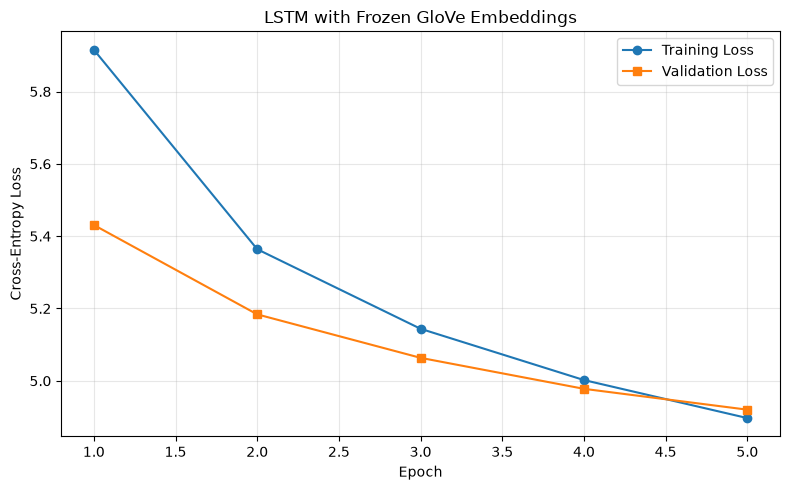

In [17]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    history["val_loss"],
    marker="s",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("LSTM with Frozen GloVe Embeddings")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "lstm_glove_loss_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [18]:
checkpoint = torch.load(
    MODELS_DIR / "lstm_glove_best.pt",
    map_location=DEVICE,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Best GloVe LSTM loaded successfully!")
print("Best epoch:", checkpoint["epoch"])
print(f"Best validation loss: {checkpoint['val_loss']:.4f}")

# Verify the embeddings have not changed
assert torch.equal(
    model.embedding.weight.detach().cpu(),
    glove_embeddings
)

print("Frozen GloVe embeddings verified!")

Best GloVe LSTM loaded successfully!
Best epoch: 5
Best validation loss: 4.9202
Frozen GloVe embeddings verified!


In [19]:
import math
import time

start_time = time.perf_counter()

test_loss = evaluate(
    model,
    test_loader,
    criterion
)

test_time = time.perf_counter() - start_time
test_ppl = math.exp(test_loss)

print(f"Test cross-entropy: {test_loss:.4f}")
print(f"Test perplexity: {test_ppl:.2f}")
print(f"Test evaluation time: {test_time:.2f} seconds")

Validation:   0%|          | 0/236 [00:00<?, ?it/s]

Test cross-entropy: 4.8445
Test perplexity: 127.03
Test evaluation time: 7.53 seconds


In [20]:
import json

glove_lstm_results = {
    "model": "LSTM Frozen GloVe",
    "embedding_type": "glove-wiki-gigaword-100",
    "embedding_frozen": True,
    "total_parameters": 2407760,
    "trainable_parameters": 1407760,
    "best_epoch": checkpoint["epoch"],
    "best_val_loss": checkpoint["val_loss"],
    "best_val_perplexity": math.exp(checkpoint["val_loss"]),
    "test_loss": test_loss,
    "test_perplexity": test_ppl,
    "test_evaluation_time_seconds": test_time,
    "lm_training_time_seconds": total_training_time,
    "history": history
}

with open(
    RESULTS_DIR / "lstm_glove_results.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(glove_lstm_results, f, indent=2)

print("GloVe LSTM results saved successfully!")

GloVe LSTM results saved successfully!
